## Data pre processing and feature engineering


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: Scikit-learn libraries for preprocessing and modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## combining the two data sets

In [2]:
# 1. Load both datasets
df_clean = pd.read_csv('diabetes.csv')
df_raw = pd.read_csv('pima_indians_diabetes.csv')

# 2. Rename columns in pima_indians_diabetes.csv to match diabetes.csv
column_mapping = {
    'preg': 'Pregnancies',
    'plas': 'Glucose',
    'pres': 'BloodPressure',
    'skin': 'SkinThickness',
    'insu': 'Insulin',
    'mass': 'BMI',
    'pedi': 'DiabetesPedigreeFunction',
    'age': 'Age',
    'class': 'Outcome'
}
df_raw = df_raw.rename(columns=column_mapping)

# 3. Convert text labels ('tested_positive'/'tested_negative') to 1 and 0
df_raw['Outcome'] = df_raw['Outcome'].map({
    'tested_positive': 1,
    'tested_negative': 0
})

# 4. Combine them vertically
combined_df = pd.concat([df_clean, df_raw], ignore_index=True)

# 5. Verify the combined dataset
print("Combined shape:", combined_df.shape)
combined_df.head()
combined_df.to_csv('combined_diabetes.csv', index=False)

Combined shape: (1536, 9)


## data cleaning and splitting

In [3]:
from sklearn.impute import KNNImputer

# 1. Load the combined dataset you created
df = pd.read_csv('combined_diabetes.csv')

# 2. Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# 3. Replace invalid 0s with NaN in medical measurement columns
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

# 4. Separate features (X) and target (y), then split into train and test sets
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Scale the features FIRST (so distance calculations in KNNImputer are fair across all columns)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

# 6. Impute missing values using the 5 most similar patients in the scaled training set
imputer = KNNImputer(n_neighbors=5)
X_train_clean = pd.DataFrame(imputer.fit_transform(X_train_scaled), columns=X.columns)
X_test_clean = pd.DataFrame(imputer.transform(X_test_scaled), columns=X.columns)

# 7. Verify results
print("Shape after drop_duplicates:", df.shape)
print("Remaining NaN values in train:", X_train_clean.isna().sum().sum())
print("Remaining NaN values in test:", X_test_clean.isna().sum().sum())
print("X_train_clean shape:", X_train_clean.shape)
print("X_test_clean shape:", X_test_clean.shape)

Shape after drop_duplicates: (1144, 9)
Remaining NaN values in train: 0
Remaining NaN values in test: 0
X_train_clean shape: (915, 8)
X_test_clean shape: (229, 8)


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0
2,8,183.0,64.0,32.0,169.5,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,1144.000000,1139.000000,1109.000000,917.000000,770.000000,1133.000000,1144.000000,1144.000000,1144.000000
mean,4.031469,121.356453,73.009919,29.103599,141.531169,32.224448,0.454343,34.055070,0.354895
std,3.402031,30.367973,12.091218,9.148291,89.107920,6.844969,0.324491,12.141609,0.478691
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,100.000000,65.000000,24.000000,102.500000,27.300000,0.236000,24.000000,0.000000
50%,3.000000,116.000000,72.000000,28.000000,102.500000,32.000000,0.344500,30.000000,0.000000
75%,6.000000,140.000000,80.000000,33.000000,169.500000,36.300000,0.597250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


C:\Users\Ram\AppData\Local\Temp\ipykernel_12952\4284985342.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=plot_df, x='Outcome', palette='Set2')


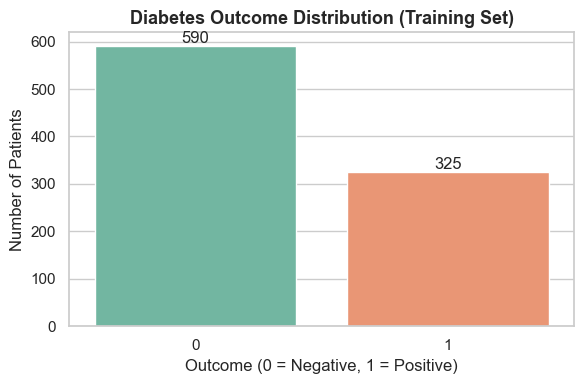

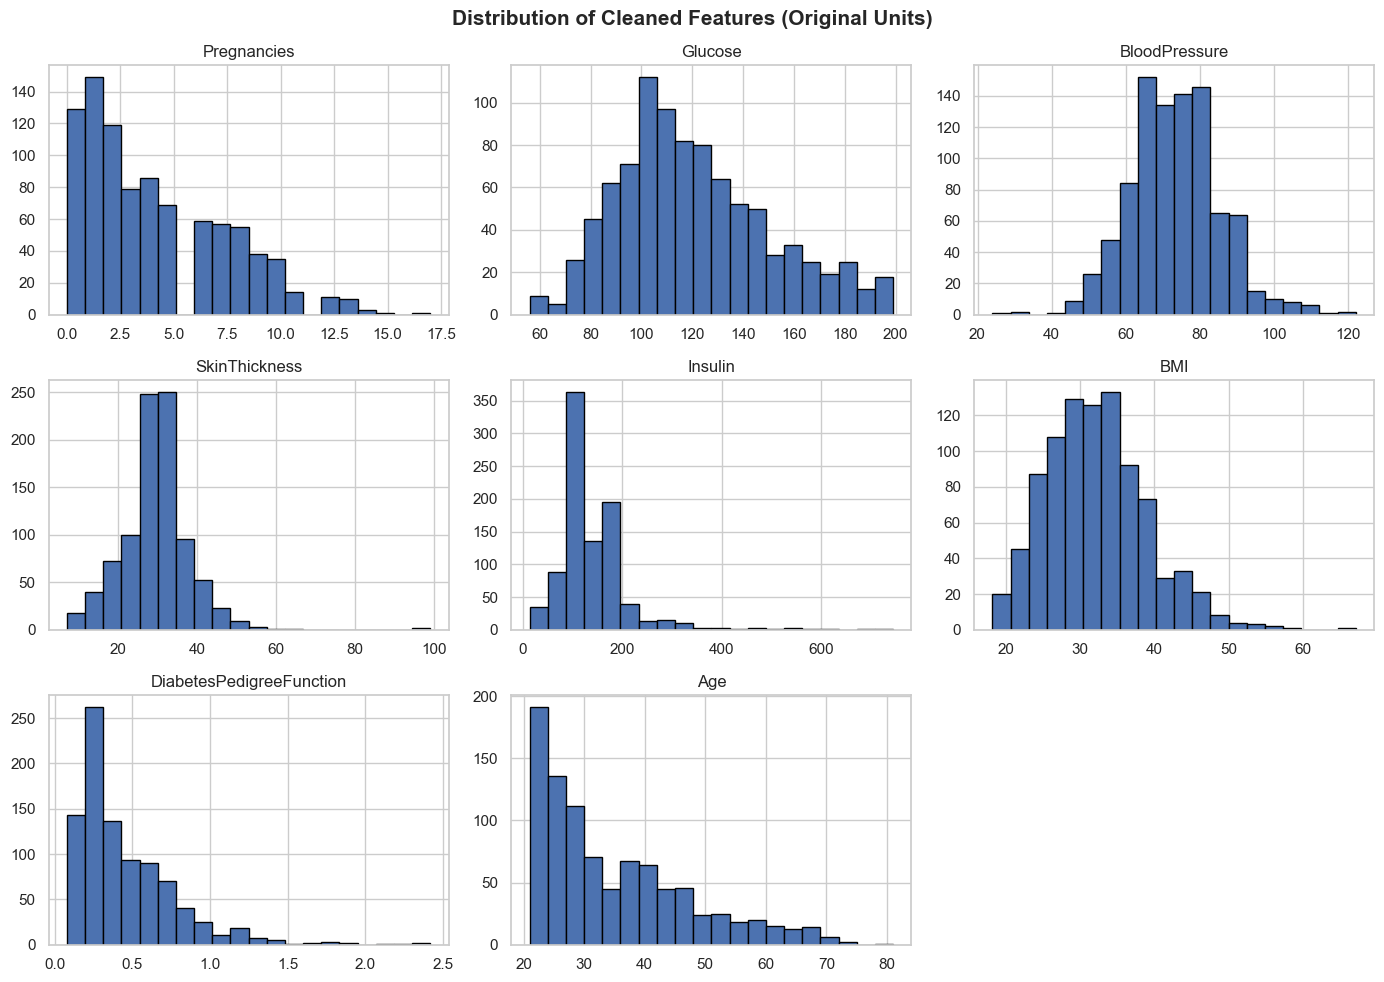

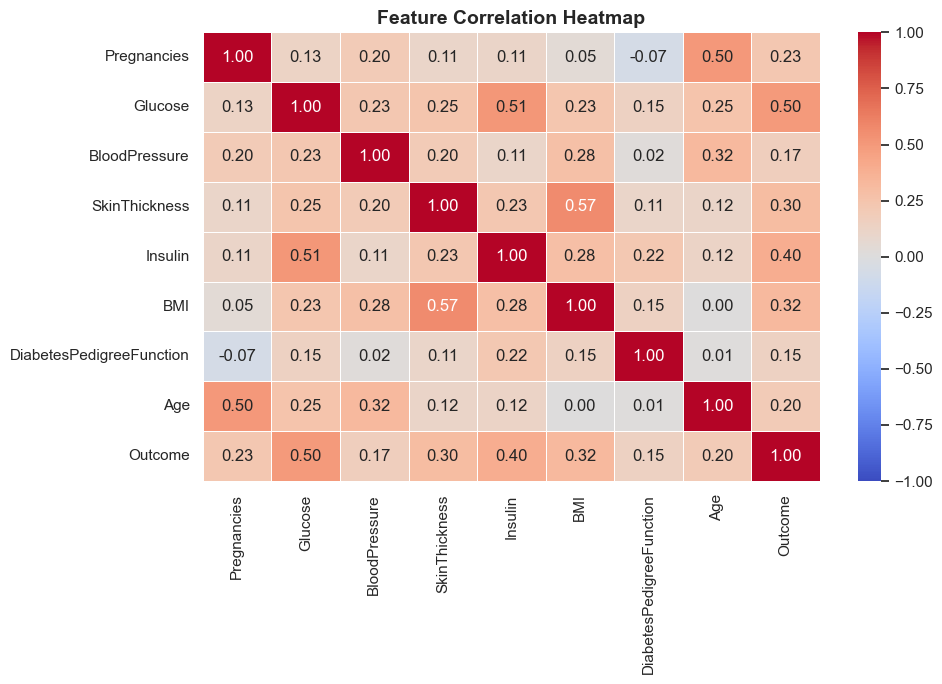

C:\Users\Ram\AppData\Local\Temp\ipykernel_12952\4284985342.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Outcome', y=col, ax=axes[row, col_idx], palette='Set2')
C:\Users\Ram\AppData\Local\Temp\ipykernel_12952\4284985342.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Outcome', y=col, ax=axes[row, col_idx], palette='Set2')
C:\Users\Ram\AppData\Local\Temp\ipykernel_12952\4284985342.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Outcome', y=col, ax=axes[row, col_idx], palette=

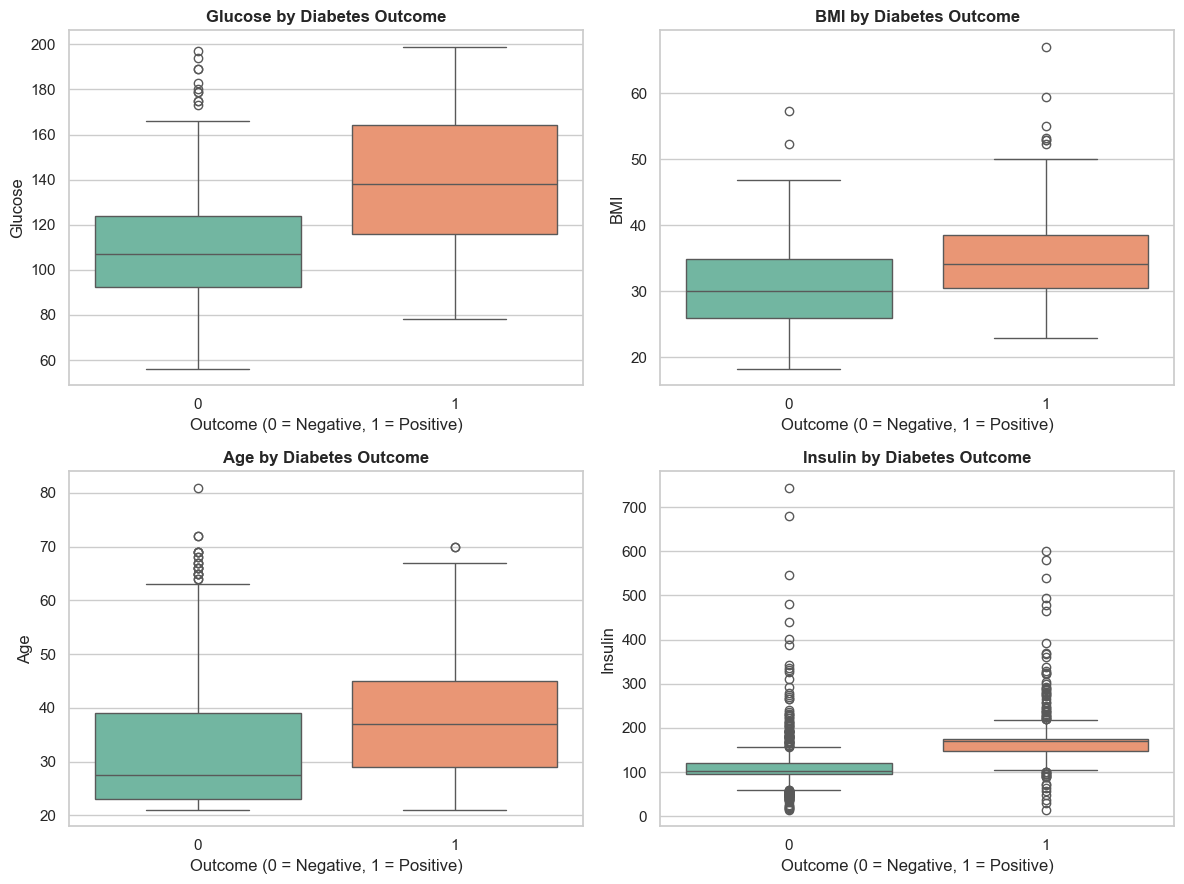

In [6]:
# 1. Convert scaled training data back to original medical units for readable charts
X_train_orig = pd.DataFrame(
    scaler.inverse_transform(X_train_clean), 
    columns=X.columns
)
plot_df = X_train_orig.copy()
plot_df['Outcome'] = y_train.values

# Set visual style
sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 2. Target Class Distribution (Diabetes vs. No Diabetes)
# ---------------------------------------------------------
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=plot_df, x='Outcome', palette='Set2')
plt.title('Diabetes Outcome Distribution (Training Set)', fontsize=13, fontweight='bold')
plt.xlabel('Outcome (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Patients')
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Feature Distributions (Histograms + KDE)
# ---------------------------------------------------------
plot_df.drop('Outcome', axis=1).hist(
    bins=20, figsize=(14, 10), color='#4C72B0', edgecolor='black'
)
plt.suptitle('Distribution of Cleaned Features (Original Units)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. Feature Correlation Heatmap
# ---------------------------------------------------------
plt.figure(figsize=(10, 7))
corr = plot_df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Boxplots: Key Risk Factors by Outcome
# ---------------------------------------------------------
key_features = ['Glucose', 'BMI', 'Age', 'Insulin']
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for idx, col in enumerate(key_features):
    row, col_idx = divmod(idx, 2)
    sns.boxplot(data=plot_df, x='Outcome', y=col, ax=axes[row, col_idx], palette='Set2')
    axes[row, col_idx].set_title(f'{col} by Diabetes Outcome', fontweight='bold')
    axes[row, col_idx].set_xlabel('Outcome (0 = Negative, 1 = Positive)')

plt.tight_layout()
plt.show()

## linear feature reduction


In [7]:
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# ---------------------------------------------------------
# 1. Principal Component Analysis (PCA) - 2 Components
# ---------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_clean)
X_test_pca = pca.transform(X_test_clean)

print("PCA Explained Variance Ratio:", np.round(pca.explained_variance_ratio_, 4))
print("PCA Total Variance Captured:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%\n")

# ---------------------------------------------------------
# 2. Linear Discriminant Analysis (LDA) - Max 1 Component (2 classes - 1)
# ---------------------------------------------------------
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train_clean, y_train)
X_test_lda = lda.transform(X_test_clean)

print("LDA Explained Variance Ratio:", np.round(lda.explained_variance_ratio_, 4))
print("X_train_lda shape:", X_train_lda.shape, "\n")

# ---------------------------------------------------------
# 3. Singular Value Decomposition (SVD) - 2 Components
# ---------------------------------------------------------
svd = TruncatedSVD(n_components=2, random_state=42)
X_train_svd = svd.fit_transform(X_train_clean)
X_test_svd = svd.transform(X_test_clean)

print("SVD Explained Variance Ratio:", np.round(svd.explained_variance_ratio_, 4))
print("SVD Total Variance Captured:", round(svd.explained_variance_ratio_.sum() * 100, 2), "%")

PCA Explained Variance Ratio: [0.3007 0.1919]
PCA Total Variance Captured: 49.26 %

LDA Explained Variance Ratio: [1.]
X_train_lda shape: (915, 1) 

SVD Explained Variance Ratio: [0.3007 0.1919]
SVD Total Variance Captured: 49.26 %


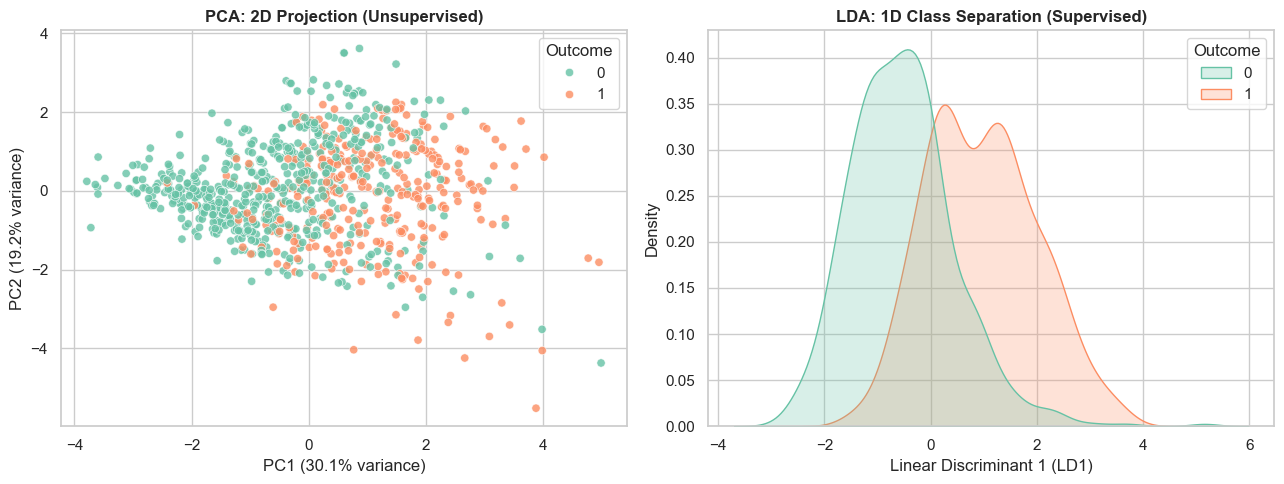

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: 2D PCA Projection
sns.scatterplot(
    x=X_train_pca[:, 0], y=X_train_pca[:, 1],
    hue=y_train, palette='Set2', alpha=0.8, ax=axes[0]
)
axes[0].set_title('PCA: 2D Projection (Unsupervised)', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')

# Plot 2: 1D LDA Projection
lda_df = pd.DataFrame({'LD1': X_train_lda.ravel(), 'Outcome': y_train.values})
sns.kdeplot(
    data=lda_df, x='LD1', hue='Outcome',
    fill=True, palette='Set2', common_norm=False, ax=axes[1]
)
axes[1].set_title('LDA: 1D Class Separation (Supervised)', fontweight='bold')
axes[1].set_xlabel('Linear Discriminant 1 (LD1)')

plt.tight_layout()
plt.show()

## non linear feature reduction

Input dataset shape: (915, 8)
Labels shape: (915,)


C:\Users\Ram\AppData\Roaming\Python\Python310\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Ram\AppData\Roaming\Python\Python310\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
C:\Users\Ram\AppData\Roaming\Python\Python310\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(



Embedding Diagnostics

Kernel PCA (RBF)
Shape: (915, 2)
Component 1 range: -0.5672767203619921 to 0.6105404595977086
Component 2 range: -0.5183781858403844 to 0.631520206142055
Component standard deviations: 0.32698646739330683 0.24975891648293472

SNE (Gaussian Low-D)
Shape: (915, 2)
Component 1 range: -3.467256358203989 to 3.946601980300947
Component 2 range: -3.2052607562733226 to 3.910150504139353
Component standard deviations: 1.716172463781295 1.7389965033480272

t-SNE (Student-t Low-D)
Shape: (915, 2)
Component 1 range: -43.754898 to 51.496643
Component 2 range: -31.3358 to 32.54297
Component standard deviations: 23.948414 15.349943

UMAP
Shape: (915, 2)
Component 1 range: -2.6564586 to 7.3690434
Component 2 range: 2.9403577 to 9.1043215
Component standard deviations: 2.653488 1.5635979

Metric MDS
Shape: (915, 2)
Component 1 range: -8.79972943521834 to 4.632500237223554
Component 2 range: -7.6629391082594935 to 5.01439543038884
Component standard deviations: 1.8216189663135793

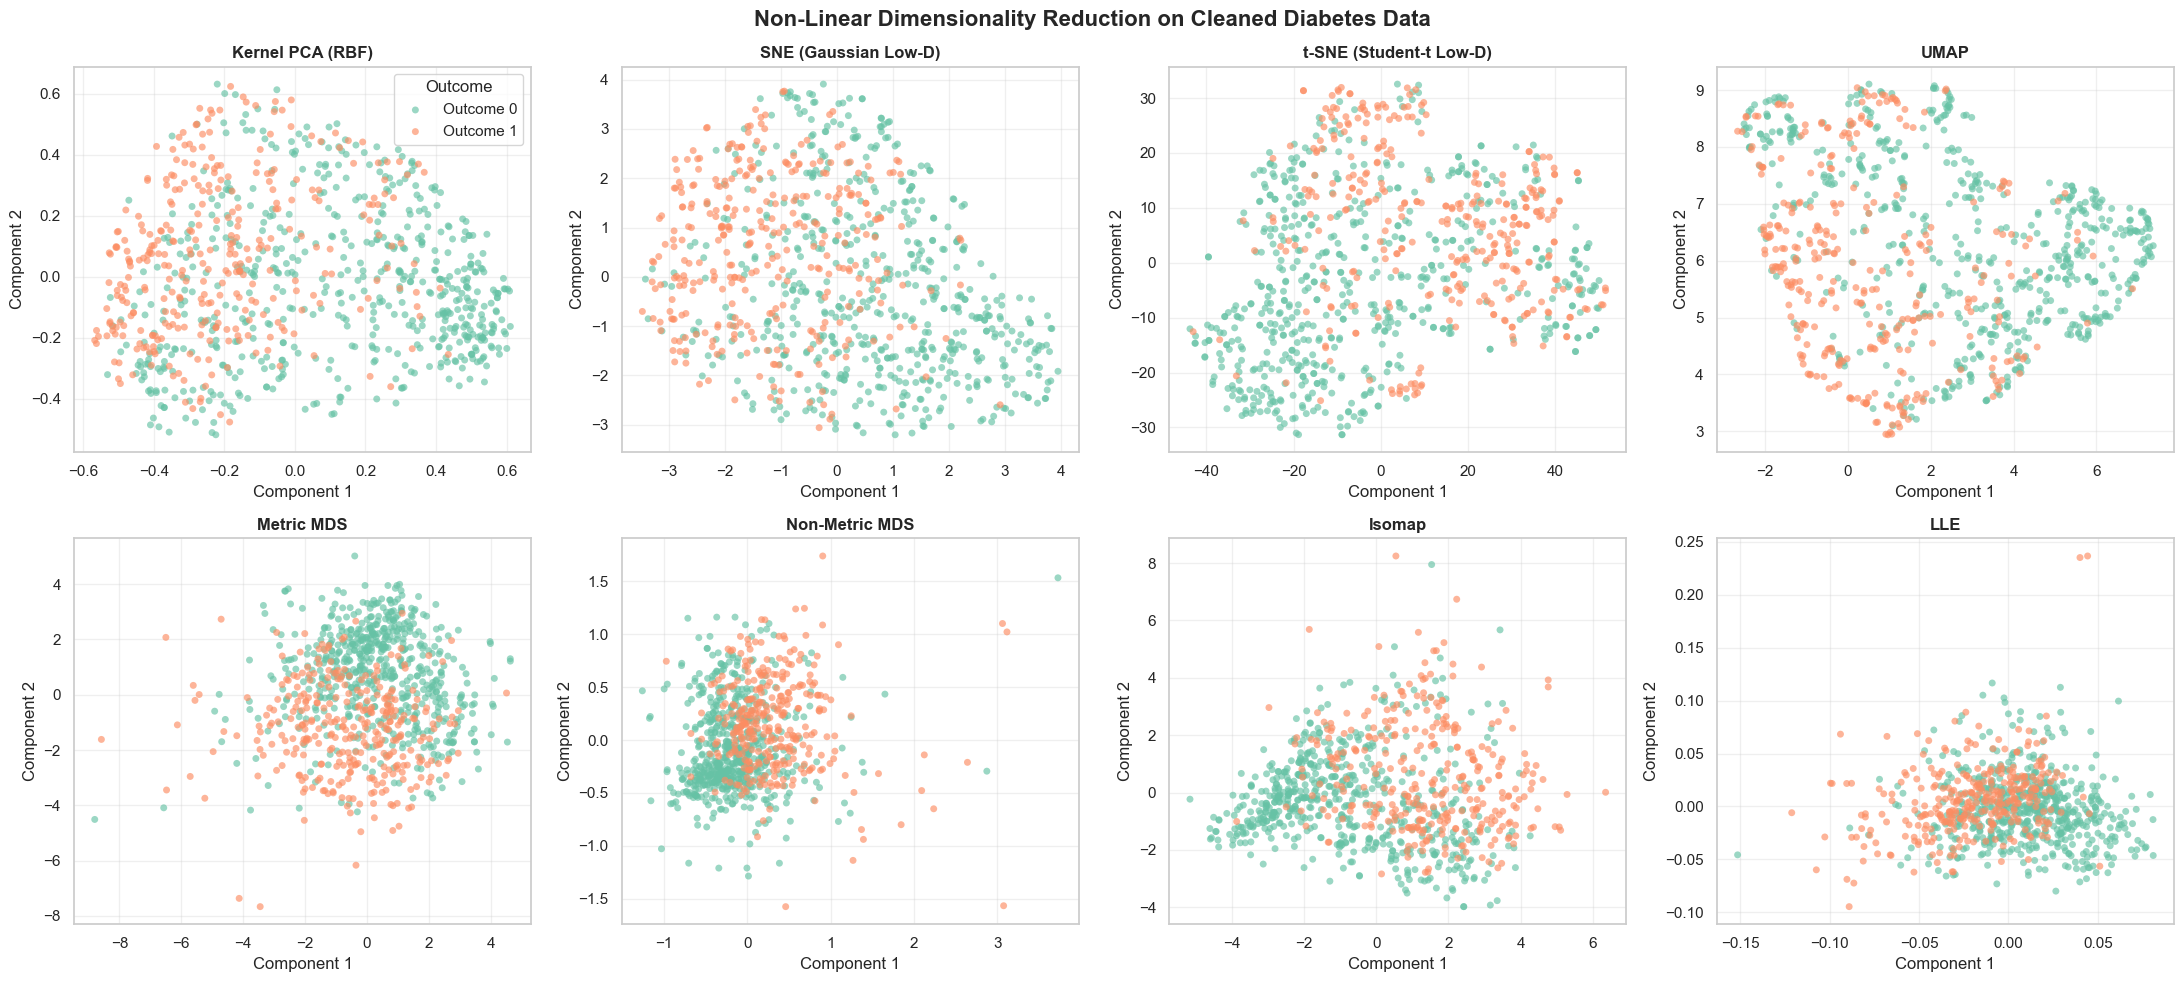

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import pdist, squareform

from sklearn.decomposition import KernelPCA
from sklearn.manifold import TSNE, MDS, Isomap, LocallyLinearEmbedding

import umap


# ============================================================
# 1. CUSTOM SYMMETRIC SNE (GAUSSIAN LOW-DIMENSIONAL SIMILARITY)
# ============================================================

def fit_symmetric_sne(
    X,
    n_components=2,
    perplexity=30.0,
    n_iter=1000,
    lr=200.0,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    n = X.shape[0]

    # Calculate squared Euclidean distances between all samples
    D = squareform(pdist(X, metric='sqeuclidean'))

    # High-dimensional probability matrix
    P = np.zeros((n, n))

    target_entropy = np.log(perplexity)

    # --------------------------------------------------------
    # Step 1: Find beta for each sample using binary search
    # --------------------------------------------------------

    for i in range(n):

        beta = 1.0
        betamin = -np.inf
        betamax = np.inf

        # Exclude the distance from a sample to itself
        Di = np.delete(D[i], i)

        for _ in range(50):

            # Gaussian similarities
            Pi = np.exp(-Di * beta)

            sum_Pi = np.sum(Pi) + 1e-12

            # Calculate entropy
            H = (
                np.log(sum_Pi)
                + beta * np.sum(Di * Pi) / sum_Pi
            )

            Hdiff = H - target_entropy

            # Stop when entropy is close to target
            if abs(Hdiff) < 1e-5:
                break

            # Adjust beta using binary search
            if Hdiff > 0:

                betamin = beta

                if betamax == np.inf:
                    beta *= 2.0
                else:
                    beta = (beta + betamax) / 2.0

            else:

                betamax = beta

                if betamin == -np.inf:
                    beta /= 2.0
                else:
                    beta = (beta + betamin) / 2.0

        # Normalize probabilities
        Pi = np.exp(-Di * beta)
        Pi /= np.sum(Pi) + 1e-12

        # Store probabilities
        P[i, np.arange(n) != i] = Pi

    # --------------------------------------------------------
    # Step 2: Symmetrize probability matrix
    # --------------------------------------------------------

    P = (P + P.T) / (2.0 * n)

    # Avoid numerical zeros
    P = np.maximum(P, 1e-12)

    # Remove self-similarity
    np.fill_diagonal(P, 0.0)

    # Normalize probabilities
    P /= np.sum(P)


    # --------------------------------------------------------
    # Step 3: Initialize low-dimensional embedding
    # --------------------------------------------------------

    Y = rng.normal(
        loc=0.0,
        scale=1e-4,
        size=(n, n_components)
    )

    velocity = np.zeros_like(Y)

    momentum = 0.5

    # --------------------------------------------------------
    # Step 4: Gradient descent optimization
    # --------------------------------------------------------

    for iteration in range(n_iter):

        # Squared distances in low-dimensional space
        sum_Y = np.sum(Y ** 2, axis=1)

        dist_Y = (
            sum_Y[:, None]
            + sum_Y[None, :]
            - 2 * (Y @ Y.T)
        )

        dist_Y = np.maximum(dist_Y, 0.0)

        # Gaussian low-dimensional similarities
        Q_num = np.exp(-dist_Y)

        np.fill_diagonal(Q_num, 0.0)

        # Normalize Q
        Q = Q_num / (np.sum(Q_num) + 1e-12)

        # Difference between high-D and low-D probabilities
        PQ = P - Q

        # ----------------------------------------------------
        # CORRECT SNE GRADIENT
        # ----------------------------------------------------

        grad = 4.0 * (
            np.sum(PQ, axis=1)[:, None] * Y
            - PQ @ Y
        )

        # Gradient clipping for numerical stability
        grad_norm = np.linalg.norm(grad)

        if grad_norm > 100:
            grad *= 100 / grad_norm

        # Momentum
        if iteration < 250:
            momentum = 0.5
        else:
            momentum = 0.8

        velocity = momentum * velocity - lr * grad

        Y += velocity

        # Center the embedding
        Y -= np.mean(Y, axis=0)

    return Y


# ============================================================
# 2. CONFIGURATION
# ============================================================

random_state = 42

# Make sure X_train_clean contains the scaled features
X = X_train_clean

# Convert to NumPy array
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)

# Labels for visualization only
y = np.asarray(y_train)

print("Input dataset shape:", X_array.shape)
print("Labels shape:", y.shape)


# ============================================================
# 3. APPLY ALL DIMENSIONALITY REDUCTION TECHNIQUES
# ============================================================

embeddings = {}


# ------------------------------------------------------------
# Kernel PCA
# ------------------------------------------------------------

embeddings["Kernel PCA (RBF)"] = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.1,
    random_state=random_state
).fit_transform(X_array)


# ------------------------------------------------------------
# Symmetric SNE
# ------------------------------------------------------------

embeddings["SNE (Gaussian Low-D)"] = fit_symmetric_sne(
    X_array,
    n_components=2,
    perplexity=30,
    n_iter=1000,
    lr=200,
    random_state=random_state
)


# ------------------------------------------------------------
# t-SNE
# ------------------------------------------------------------

embeddings["t-SNE (Student-t Low-D)"] = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=random_state
).fit_transform(X_array)


# ------------------------------------------------------------
# UMAP
# ------------------------------------------------------------

embeddings["UMAP"] = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=random_state
).fit_transform(X_array)


# ------------------------------------------------------------
# Metric MDS
# ------------------------------------------------------------

embeddings["Metric MDS"] = MDS(
    n_components=2,
    metric=True,
    random_state=random_state,
    normalized_stress="auto",
    max_iter=300
).fit_transform(X_array)


# ------------------------------------------------------------
# Non-Metric MDS
# ------------------------------------------------------------

embeddings["Non-Metric MDS"] = MDS(
    n_components=2,
    metric=False,
    random_state=random_state,
    normalized_stress="auto",
    max_iter=300
).fit_transform(X_array)


# ------------------------------------------------------------
# Isomap
# ------------------------------------------------------------

embeddings["Isomap"] = Isomap(
    n_components=2,
    n_neighbors=15,
    eigen_solver="auto"
).fit_transform(X_array)


# ------------------------------------------------------------
# LLE - IMPROVED CONFIGURATION
# ------------------------------------------------------------

embeddings["LLE"] = LocallyLinearEmbedding(
    n_components=2,
    n_neighbors=15,
    method="standard",
    eigen_solver="dense",
    reg=1e-3,
    random_state=random_state
).fit_transform(X_array)


# ============================================================
# 4. CHECK EMBEDDING SHAPES AND VARIATION
# ============================================================

print("\nEmbedding Diagnostics")
print("=" * 60)

for name, X_embedded in embeddings.items():

    print(f"\n{name}")

    print("Shape:", X_embedded.shape)

    print("Component 1 range:",
          np.min(X_embedded[:, 0]),
          "to",
          np.max(X_embedded[:, 0]))

    print("Component 2 range:",
          np.min(X_embedded[:, 1]),
          "to",
          np.max(X_embedded[:, 1]))

    print("Component standard deviations:",
          np.std(X_embedded[:, 0]),
          np.std(X_embedded[:, 1]))

    # Check if the embedding is almost collapsed
    if np.std(X_embedded[:, 0]) < 1e-5 or np.std(X_embedded[:, 1]) < 1e-5:
        print("WARNING: One component has very little variation!")


# ============================================================
# 5. VISUALIZE ALL 8 METHODS
# ============================================================

fig, axes = plt.subplots(
    2,
    4,
    figsize=(22, 10)
)

axes = axes.ravel()

palette = {
    0: "#66C2A5",
    1: "#FC8D62"
}


for idx, (name, X_embedded) in enumerate(embeddings.items()):

    ax = axes[idx]

    # Plot class 0
    mask_0 = y == 0

    ax.scatter(
        X_embedded[mask_0, 0],
        X_embedded[mask_0, 1],
        color=palette[0],
        label="Outcome 0",
        alpha=0.65,
        s=25,
        edgecolors="none"
    )

    # Plot class 1
    mask_1 = y == 1

    ax.scatter(
        X_embedded[mask_1, 0],
        X_embedded[mask_1, 1],
        color=palette[1],
        label="Outcome 1",
        alpha=0.65,
        s=25,
        edgecolors="none"
    )

    ax.set_title(
        name,
        fontweight="bold",
        fontsize=12
    )

    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

    ax.grid(True, alpha=0.3)

    # Show legend only in first plot
    if idx == 0:

        ax.legend(
            title="Outcome",
            loc="best"
        )


# ------------------------------------------------------------
# Final layout
# ------------------------------------------------------------

plt.suptitle(
    "Non-Linear Dimensionality Reduction on Cleaned Diabetes Data",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## feature selection

In [10]:
import pandas as pd
from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SequentialFeatureSelector, RFECV
from sklearn.model_selection import cross_val_score

# Base classifier wrapped inside the feature selectors
clf = LogisticRegression(max_iter=1000, random_state=42)
feature_names = X_train_clean.columns

# ---------------------------------------------------------
# 1. Forward Feature Selection (Top 4 Features)
# ---------------------------------------------------------
sfs_forward = SequentialFeatureSelector(
    clf, n_features_to_select=4, direction='forward', scoring='roc_auc', cv=5
)
sfs_forward.fit(X_train_clean, y_train)
print("Forward Selection (Top 4):", list(feature_names[sfs_forward.get_support()]))

# ---------------------------------------------------------
# 2. Backward Feature Elimination (Top 4 Features)
# ---------------------------------------------------------
sfs_backward = SequentialFeatureSelector(
    clf, n_features_to_select=4, direction='backward', scoring='roc_auc', cv=5
)
sfs_backward.fit(X_train_clean, y_train)
print("Backward Elimination (Top 4):", list(feature_names[sfs_backward.get_support()]))

# ---------------------------------------------------------
# 3. Recursive Feature Elimination with Cross-Validation (RFECV)
# ---------------------------------------------------------
rfecv = RFECV(estimator=clf, step=1, cv=5, scoring='roc_auc')
rfecv.fit(X_train_clean, y_train)
print(f"RFECV Optimal Count ({rfecv.n_features_} features):", list(feature_names[rfecv.support_]))

# ---------------------------------------------------------
# 4. Exhaustive Feature Selection (All 255 Combinations)
# ---------------------------------------------------------
best_score = 0
best_subset = None

for k in range(1, len(feature_names) + 1):
    for subset in combinations(feature_names, k):
        cols = list(subset)
        score = cross_val_score(clf, X_train_clean[cols], y_train, cv=5, scoring='roc_auc').mean()
        if score > best_score:
            best_score = score
            best_subset = cols

print(f"Exhaustive Best Subset (ROC-AUC = {best_score:.4f}):", best_subset)

Forward Selection (Top 4): ['SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction']
Backward Elimination (Top 4): ['Pregnancies', 'Glucose', 'Insulin', 'BMI']
RFECV Optimal Count (7 features): ['Pregnancies', 'Glucose', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Exhaustive Best Subset (ROC-AUC = 0.8577): ['Pregnancies', 'Glucose', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction']


L1 (Lasso) -> Kept (7/8): ['Pregnancies', 'Glucose', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
L2 (Ridge) -> Kept (8/8): ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Elastic Net (50/50) -> Kept (8/8): ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Feature Coefficients Comparison:


,L1 (Lasso),L2 (Ridge),Elastic Net (50/50)
Pregnancies,0.3916,0.4043,0.3976
Glucose,0.9021,0.8989,0.8997
BloodPressure,0.0000,-0.0576,-0.0269
SkinThickness,0.3162,0.3463,0.3313
Insulin,0.4966,0.5252,0.5113
BMI,0.3783,0.4051,0.3912
DiabetesPedigreeFunction,0.1155,0.1458,0.1306
Age,0.0363,0.0834,0.0598


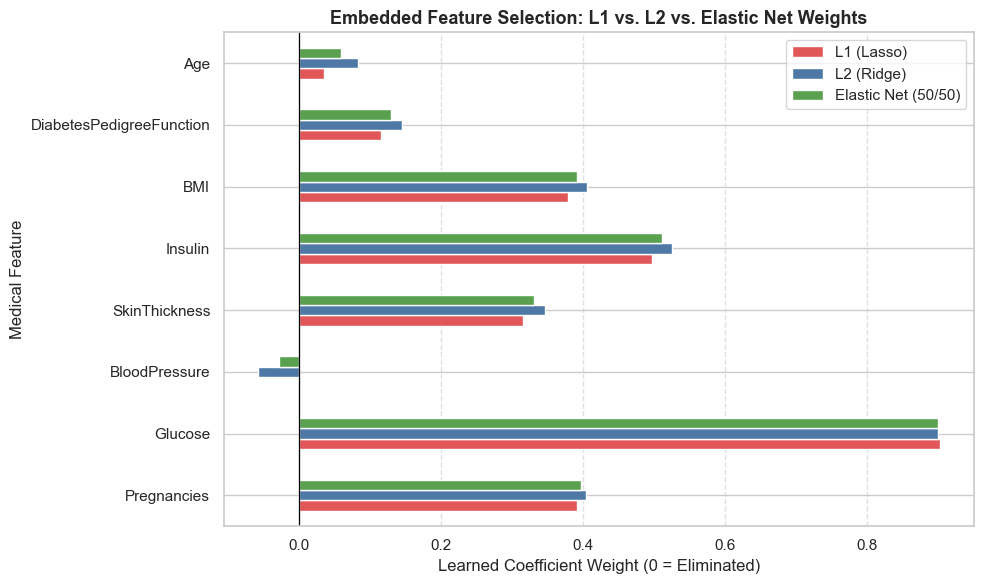

X_train_l1 shape: (915, 7)


C:\Users\Ram\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
C:\Users\Ram\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

feature_names = X_train_clean.columns

# 1. Train Logistic Regression with L1 (Lasso), L2 (Ridge), and Elastic Net
models = {
    'L1 (Lasso)': LogisticRegression(penalty='l1', C=0.2, solver='saga', max_iter=2000, random_state=42),
    'L2 (Ridge)': LogisticRegression(penalty='l2', C=0.2, solver='saga', max_iter=2000, random_state=42),
    'Elastic Net (50/50)': LogisticRegression(penalty='elasticnet', l1_ratio=0.5, C=0.2, solver='saga', max_iter=2000, random_state=42)
}

weights_df = pd.DataFrame(index=feature_names)

for name, model in models.items():
    model.fit(X_train_clean, y_train)
    weights_df[name] = model.coef_[0]
    
    # Show which features survive with non-zero weights
    selected = feature_names[np.abs(model.coef_[0]) > 1e-5].tolist()
    print(f"{name} -> Kept ({len(selected)}/8): {selected}")

print("\nFeature Coefficients Comparison:")
display(weights_df.round(4))

# 2. Plot Coefficient Shrinkage Across All Three Penalties
weights_df.plot(kind='barh', figsize=(10, 6), color=['#E15759', '#4E79A7', '#59A14F'])
plt.axvline(0, color='black', linewidth=0.9)
plt.title('Embedded Feature Selection: L1 vs. L2 vs. Elastic Net Weights', fontsize=13, fontweight='bold')
plt.xlabel('Learned Coefficient Weight (0 = Eliminated)')
plt.ylabel('Medical Feature')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Extract Selected Features into Clean Datasets Using SelectFromModel (L1 example)
selector = SelectFromModel(models['L1 (Lasso)'], prefit=True)
X_train_l1 = pd.DataFrame(selector.transform(X_train_clean), columns=feature_names[selector.get_support()])
X_test_l1 = pd.DataFrame(selector.transform(X_test_clean), columns=feature_names[selector.get_support()])

print("X_train_l1 shape:", X_train_l1.shape)


GA Binary Chromosome: [1 1 0 1 1 1 0 0]
GA Selected Features: ['Pregnancies', 'Glucose', 'SkinThickness', 'Insulin', 'BMI']


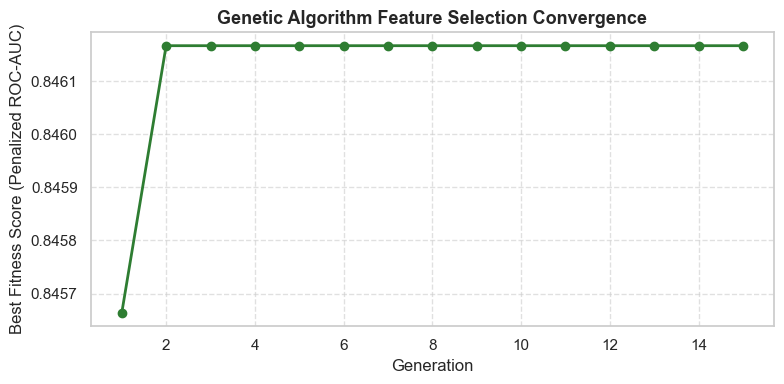

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def genetic_feature_selection(X, y, pop_size=20, n_generations=15, mutation_rate=0.1, penalty=0.002, random_state=42):
    rng = np.random.default_rng(random_state)
    n_features = X.shape[1]
    clf = LogisticRegression(max_iter=1000, random_state=random_state)
    
    # 1. Initialize random binary population (ensure at least 1 feature is active per chromosome)
    population = rng.integers(0, 2, size=(pop_size, n_features))
    for i in range(pop_size):
        if population[i].sum() == 0:
            population[i, rng.integers(0, n_features)] = 1

    best_history = []
    best_chromosome = None
    best_fitness = -np.inf

    for gen in range(n_generations):
        fitness_scores = np.zeros(pop_size)
        
        # 2. Evaluate fitness of each chromosome (ROC-AUC minus small feature-count penalty)
        for i, chrom in enumerate(population):
            if chrom.sum() == 0:
                fitness_scores[i] = 0.0
                continue
            cols = X.columns[chrom == 1]
            auc = cross_val_score(clf, X[cols], y, cv=5, scoring='roc_auc').mean()
            fitness_scores[i] = auc - penalty * chrom.sum()

        # Track global best
        gen_best_idx = np.argmax(fitness_scores)
        if fitness_scores[gen_best_idx] > best_fitness:
            best_fitness = fitness_scores[gen_best_idx]
            best_chromosome = population[gen_best_idx].copy()
        best_history.append(best_fitness)

        # 3. Tournament Selection (pick fittest parents)
        parents = []
        for _ in range(pop_size):
            i, j = rng.choice(pop_size, size=2, replace=False)
            parents.append(population[i] if fitness_scores[i] > fitness_scores[j] else population[j])
        parents = np.array(parents)

        # 4. Single-Point Crossover + Mutation to form next generation
        next_pop = [best_chromosome.copy()]  # Elitism: always carry the best forward
        while len(next_pop) < pop_size:
            p1, p2 = parents[rng.choice(pop_size, size=2, replace=False)]
            cut = rng.integers(1, n_features)
            child = np.concatenate([p1[:cut], p2[cut:]])
            
            # Random bit-flip mutation
            mut_mask = rng.random(n_features) < mutation_rate
            child = np.where(mut_mask, 1 - child, child)
            if child.sum() == 0:
                child[rng.integers(0, n_features)] = 1
            next_pop.append(child)
            
        population = np.array(next_pop)

    selected_features = list(X.columns[best_chromosome == 1])
    return selected_features, best_chromosome, best_history

# Run Genetic Algorithm on cleaned training data
ga_features, ga_mask, ga_history = genetic_feature_selection(X_train_clean, y_train)

print("GA Binary Chromosome:", ga_mask)
print("GA Selected Features:", ga_features)

# Plot fitness evolution across generations
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ga_history) + 1), ga_history, marker='o', color='#2E7D32', linewidth=2)
plt.title('Genetic Algorithm Feature Selection Convergence', fontsize=13, fontweight='bold')
plt.xlabel('Generation')
plt.ylabel('Best Fitness Score (Penalized ROC-AUC)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Create filtered train/test sets using GA-selected features
X_train_ga = X_train_clean[ga_features]
X_test_ga = X_test_clean[ga_features]

## diffrent model implementations and evaluations

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
)

# 1. Define a diverse set of classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),
    'Support Vector Machine (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42)
}

# 2. Helper function to train and evaluate on both All Features and GA-Selected Features
def evaluate_models(X_tr, X_te, feature_set_label):
    records = []
    for name, model in models.items():
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_te)
        y_prob = model.predict_proba(X_te)[:, 1]
        
        records.append({
            'Feature Set': feature_set_label,
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall (Sensitivity)': recall_score(y_test, y_pred),
            'F1-Score': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_prob)
        })
    return pd.DataFrame(records)

# Run benchmark on both feature sets
results_all = evaluate_models(X_train_clean, X_test_clean, 'All 8 Features')
results_ga = evaluate_models(X_train_ga, X_test_ga, f'GA Selected ({len(ga_features)} Features)')

# Combine and sort by ROC-AUC
comparison_df = pd.concat([results_all, results_ga], ignore_index=True)
comparison_df = comparison_df.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

display(comparison_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall (Sensitivity)': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}).background_gradient(subset=['ROC-AUC', 'F1-Score'], cmap='Greens'))

,Feature Set,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,ROC-AUC
0,All 8 Features,Gradient Boosting,0.8559,0.7927,0.8025,0.7975,0.9426
1,GA Selected (5 Features),Gradient Boosting,0.8297,0.7692,0.7407,0.7547,0.9317
2,All 8 Features,Random Forest,0.8384,0.7558,0.8025,0.7784,0.9303
3,GA Selected (5 Features),Random Forest,0.8515,0.7765,0.8148,0.7952,0.9263
4,All 8 Features,Support Vector Machine (RBF),0.8253,0.7531,0.7531,0.7531,0.8961
5,GA Selected (5 Features),Decision Tree,0.8210,0.8448,0.6049,0.7050,0.8922
6,All 8 Features,Decision Tree,0.8384,0.7200,0.8889,0.7956,0.8851
7,GA Selected (5 Features),Support Vector Machine (RBF),0.8341,0.7471,0.8025,0.7738,0.8817
8,GA Selected (5 Features),K-Nearest Neighbors (KNN),0.8253,0.7356,0.7901,0.7619,0.8712
9,All 8 Features,K-Nearest Neighbors (KNN),0.8079,0.7126,0.7654,0.7381,0.8700


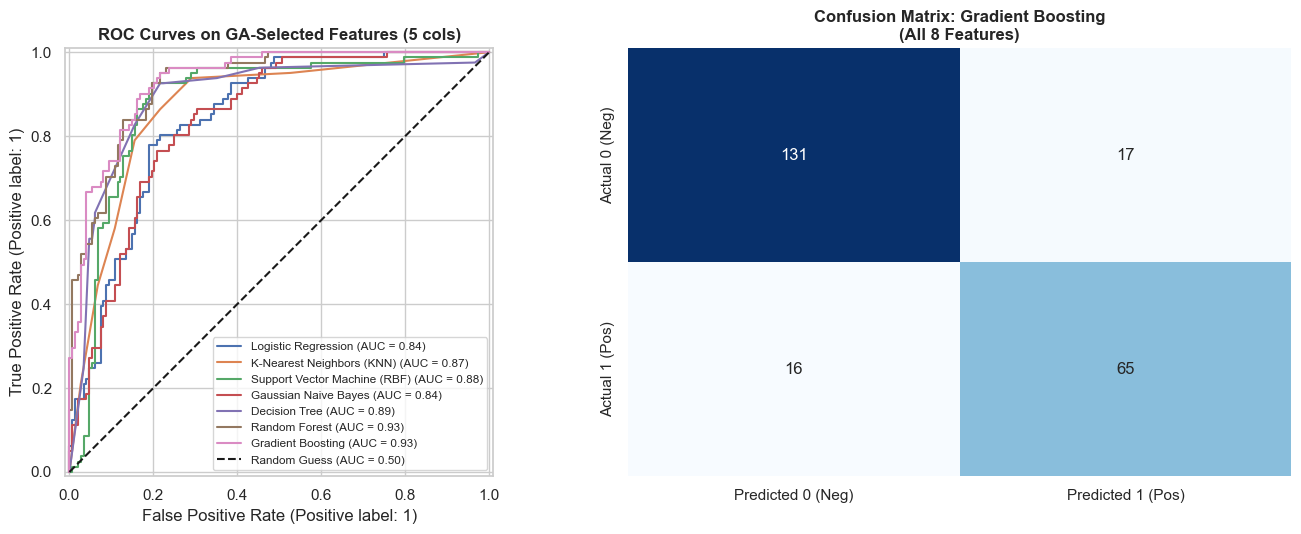

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Overlaid ROC Curves (on GA-Selected Features)
for name, model in models.items():
    model.fit(X_train_ga, y_train)
    RocCurveDisplay.from_estimator(model, X_test_ga, y_test, ax=axes[0], name=name)

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
axes[0].set_title(f'ROC Curves on GA-Selected Features ({len(ga_features)} cols)', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=8.5)

# 2. Confusion Matrix for the Top-Ranked Model
best_row = comparison_df.iloc[0]
best_model_name = best_row['Model']
best_model = models[best_model_name]

if 'GA' in best_row['Feature Set']:
    best_model.fit(X_train_ga, y_train)
    y_best_pred = best_model.predict(X_test_ga)
else:
    best_model.fit(X_train_clean, y_train)
    y_best_pred = best_model.predict(X_test_clean)

cm = confusion_matrix(y_test, y_best_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
    xticklabels=['Predicted 0 (Neg)', 'Predicted 1 (Pos)'],
    yticklabels=['Actual 0 (Neg)', 'Actual 1 (Pos)']
)
axes[1].set_title(f'Confusion Matrix: {best_model_name}\n({best_row["Feature Set"]})', fontweight='bold')

plt.tight_layout()
plt.show()

Tree-Based GA Selected Features: ['Glucose', 'BloodPressure', 'Insulin', 'BMI', 'Age']
Best Hyperparameters: {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 3, 'n_estimators': 150, 'subsample': 1.0}
Best 5-Fold CV ROC-AUC: 0.9203



,Threshold,Accuracy,Precision,Recall (Sensitivity),F1-Score,False Negatives (Missed),False Positives (Alarms)
0,0.50,0.8646,0.7907,0.8395,0.8144,13,18
1,0.40,0.8515,0.7327,0.9136,0.8132,7,27
2,0.35,0.8559,0.7308,0.9383,0.8216,5,28
3,0.30,0.8559,0.7264,0.9506,0.8235,4,29


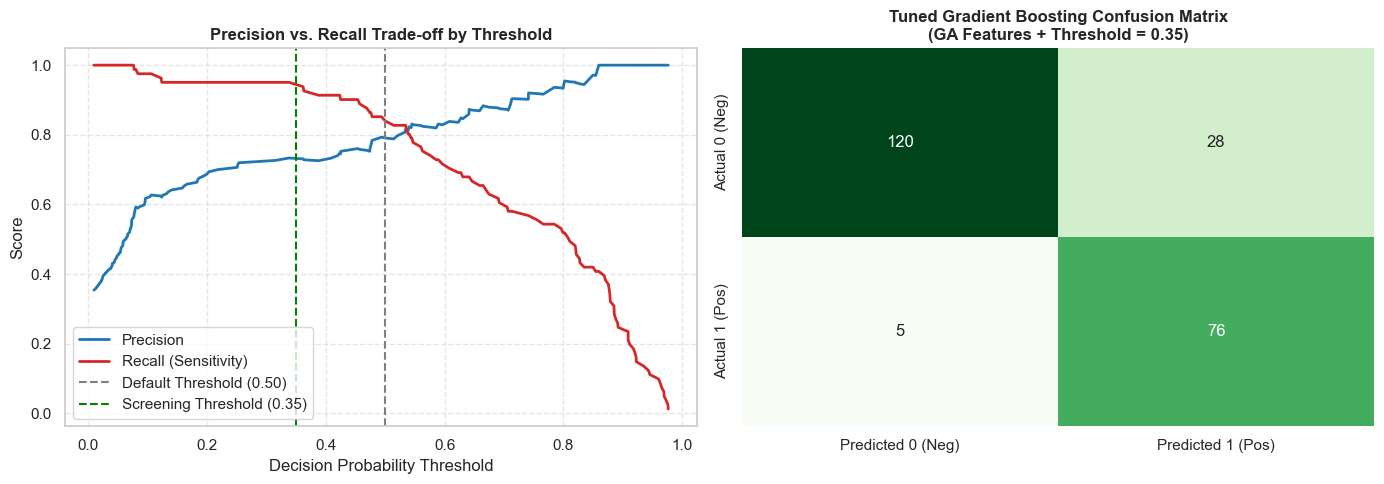

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, precision_recall_curve
)

# =========================================================
# PART 1: Tree-Based Genetic Algorithm (Gradient Boosting)
# =========================================================
def genetic_feature_selection_gb(X, y, pop_size=16, n_generations=12, mutation_rate=0.12, penalty=0.001, random_state=42):
    rng = np.random.default_rng(random_state)
    n_features = X.shape[1]
    base_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=random_state)

    population = rng.integers(0, 2, size=(pop_size, n_features))
    for i in range(pop_size):
        if population[i].sum() == 0:
            population[i, rng.integers(0, n_features)] = 1

    best_chromosome = None
    best_fitness = -np.inf

    for gen in range(n_generations):
        fitness_scores = np.zeros(pop_size)
        for i, chrom in enumerate(population):
            if chrom.sum() == 0:
                continue
            cols = X.columns[chrom == 1]
            auc = cross_val_score(base_gb, X[cols], y, cv=5, scoring='roc_auc', n_jobs=-1).mean()
            fitness_scores[i] = auc - penalty * chrom.sum()

        gen_best_idx = np.argmax(fitness_scores)
        if fitness_scores[gen_best_idx] > best_fitness:
            best_fitness = fitness_scores[gen_best_idx]
            best_chromosome = population[gen_best_idx].copy()

        # Tournament selection
        parents = np.array([
            population[i] if fitness_scores[i] > fitness_scores[j] else population[j]
            for i, j in (rng.choice(pop_size, size=2, replace=False) for _ in range(pop_size))
        ])

        # Elitism + Crossover + Mutation
        next_pop = [best_chromosome.copy()]
        while len(next_pop) < pop_size:
            p1, p2 = parents[rng.choice(pop_size, size=2, replace=False)]
            cut = rng.integers(1, n_features)
            child = np.concatenate([p1[:cut], p2[cut:]])
            mut_mask = rng.random(n_features) < mutation_rate
            child = np.where(mut_mask, 1 - child, child)
            if child.sum() == 0:
                child[rng.integers(0, n_features)] = 1
            next_pop.append(child)

        population = np.array(next_pop)

    return list(X.columns[best_chromosome == 1]), best_chromosome

ga_gb_features, ga_gb_mask = genetic_feature_selection_gb(X_train_clean, y_train)
print("Tree-Based GA Selected Features:", ga_gb_features)

X_train_gb_ga = X_train_clean[ga_gb_features]
X_test_gb_ga = X_test_clean[ga_gb_features]

# =========================================================
# PART 2: Hyperparameter Tuning (GridSearchCV)
# =========================================================
param_grid = {
    'n_estimators': [100, 150, 250],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0],
    'min_samples_leaf': [3, 5]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
grid_search.fit(X_train_gb_ga, y_train)

best_gb = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best 5-Fold CV ROC-AUC: {grid_search.best_score_:.4f}\n")

# =========================================================
# PART 3: Decision Threshold Optimization (Cutting False Negatives)
# =========================================================
y_probs = best_gb.predict_proba(X_test_gb_ga)[:, 1]

# Compare default 0.50 threshold vs. lower screening thresholds
thresholds_to_test = [0.50, 0.40, 0.35, 0.30]
summary_rows = []

for thresh in thresholds_to_test:
    preds = (y_probs >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    summary_rows.append({
        'Threshold': thresh,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall (Sensitivity)': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'False Negatives (Missed)': fn,
        'False Positives (Alarms)': fp
    })

thresh_df = pd.DataFrame(summary_rows)
display(thresh_df.style.format({
    'Threshold': '{:.2f}',
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall (Sensitivity)': '{:.4f}',
    'F1-Score': '{:.4f}'
}))

# =========================================================
# PART 4: Visual Comparison (Threshold Curve & Tuned Confusion Matrix)
# =========================================================
chosen_threshold = 0.35
y_pred_tuned = (y_probs >= chosen_threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Precision & Recall across all possible thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)
axes[0].plot(thresholds, precisions[:-1], label='Precision', color='#1f77b4', linewidth=2)
axes[0].plot(thresholds, recalls[:-1], label='Recall (Sensitivity)', color='#d62728', linewidth=2)
axes[0].axvline(0.50, color='gray', linestyle='--', label='Default Threshold (0.50)')
axes[0].axvline(chosen_threshold, color='green', linestyle='--', label=f'Screening Threshold ({chosen_threshold})')
axes[0].set_title('Precision vs. Recall Trade-off by Threshold', fontweight='bold')
axes[0].set_xlabel('Decision Probability Threshold')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Confusion Matrix at chosen threshold (0.35)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(
    cm_tuned, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
    xticklabels=['Predicted 0 (Neg)', 'Predicted 1 (Pos)'],
    yticklabels=['Actual 0 (Neg)', 'Actual 1 (Pos)']
)
axes[1].set_title(f'Tuned Gradient Boosting Confusion Matrix\n(GA Features + Threshold = {chosen_threshold})', fontweight='bold')

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

# 1. Base models used in benchmarking
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),
    'Support Vector Machine (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42)
}

# 2. Feature subsets created in earlier cells (automatically includes whichever exist in memory)
feature_sets = [('All 8 Features', X_train_clean, X_test_clean)]
if 'X_train_ga' in globals():
    feature_sets.append((f'Logistic-GA ({X_train_ga.shape[1]} Features)', X_train_ga, X_test_ga))
if 'X_train_gb_ga' in globals():
    feature_sets.append((f'Tree-GA ({X_train_gb_ga.shape[1]} Features)', X_train_gb_ga, X_test_gb_ga))

# 3. Helper function to calculate all 7 requested metrics
def get_metrics_row(pipeline_label, model_name, y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    acc = accuracy_score(y_true, y_pred)
    err = 1.0 - acc
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    return {
        'Pipeline / Feature Set': pipeline_label,
        'Model': model_name,
        'Confusion Matrix [[TN, FP], [FN, TP]]': f"[[{tn}, {fp}], [{fn}, {tp}]]",
        'Accuracy': acc,
        'Error Rate': err,
        'Precision': prec,
        'Recall': rec,
        'F-measure (F1)': f1,
        'ROC - AUC': auc
    }

all_results = []

# Evaluate all 7 models across every feature subset
for fs_label, X_tr, X_te in feature_sets:
    for model_name, model_template in base_models.items():
        clf = clone(model_template)
        clf.fit(X_tr, y_train)
        y_pred = clf.predict(X_te)
        y_prob = clf.predict_proba(X_te)[:, 1]
        all_results.append(get_metrics_row(fs_label, model_name, y_test, y_pred, y_prob))

# Evaluate Tuned Gradient Boosting (Default 0.50 & Screening 0.35 Thresholds) if run earlier
if 'best_gb' in globals() and 'X_test_gb_ga' in globals():
    y_prob_tuned = best_gb.predict_proba(X_test_gb_ga)[:, 1]
    for thresh in [0.50, 0.35]:
        y_pred_t = (y_prob_tuned >= thresh).astype(int)
        all_results.append(
            get_metrics_row(
                f'Tuned Tree-GA (Threshold={thresh:.2f})',
                'Gradient Boosting (Tuned)',
                y_test, y_pred_t, y_prob_tuned
            )
        )

# 4. Build, sort, and display the complete metrics table
full_metrics_df = pd.DataFrame(all_results).sort_values(by='ROC - AUC', ascending=False).reset_index(drop=True)

# Print detailed text breakdown per model
for _, row in full_metrics_df.iterrows():
    print(f"{'='*70}")
    print(f"Model: {row['Model']} | Set: {row['Pipeline / Feature Set']}")
    print(f"  Confusion Matrix : {row['Confusion Matrix [[TN, FP], [FN, TP]]']}")
    print(f"  Accuracy         : {row['Accuracy']:.4f}  |  Error Rate : {row['Error Rate']:.4f}")
    print(f"  Precision        : {row['Precision']:.4f}  |  Recall     : {row['Recall']:.4f}")
    print(f"  F-measure (F1)   : {row['F-measure (F1)']:.4f}  |  ROC - AUC  : {row['ROC - AUC']:.4f}")

# Display formatted summary DataFrame
display(
    full_metrics_df.style.format({
        'Accuracy': '{:.4f}',
        'Error Rate': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F-measure (F1)': '{:.4f}',
        'ROC - AUC': '{:.4f}'
    }).background_gradient(subset=['ROC - AUC', 'F-measure (F1)', 'Recall'], cmap='Greens')
)

Model: Gradient Boosting | Set: All 8 Features
  Confusion Matrix : [[131, 17], [16, 65]]
  Accuracy         : 0.8559  |  Error Rate : 0.1441
  Precision        : 0.7927  |  Recall     : 0.8025
  F-measure (F1)   : 0.7975  |  ROC - AUC  : 0.9426
Model: Gradient Boosting (Tuned) | Set: Tuned Tree-GA (Threshold=0.35)
  Confusion Matrix : [[120, 28], [5, 76]]
  Accuracy         : 0.8559  |  Error Rate : 0.1441
  Precision        : 0.7308  |  Recall     : 0.9383
  F-measure (F1)   : 0.8216  |  ROC - AUC  : 0.9422
Model: Gradient Boosting (Tuned) | Set: Tuned Tree-GA (Threshold=0.50)
  Confusion Matrix : [[130, 18], [13, 68]]
  Accuracy         : 0.8646  |  Error Rate : 0.1354
  Precision        : 0.7907  |  Recall     : 0.8395
  F-measure (F1)   : 0.8144  |  ROC - AUC  : 0.9422
Model: Gradient Boosting | Set: Tree-GA (5 Features)
  Confusion Matrix : [[135, 13], [15, 66]]
  Accuracy         : 0.8777  |  Error Rate : 0.1223
  Precision        : 0.8354  |  Recall     : 0.8148
  F-measure (F1

,Pipeline / Feature Set,Model,"Confusion Matrix [[TN, FP], [FN, TP]]",Accuracy,Error Rate,Precision,Recall,F-measure (F1),ROC - AUC
0,All 8 Features,Gradient Boosting,"[[131, 17], [16, 65]]",0.8559,0.1441,0.7927,0.8025,0.7975,0.9426
1,Tuned Tree-GA (Threshold=0.35),Gradient Boosting (Tuned),"[[120, 28], [5, 76]]",0.8559,0.1441,0.7308,0.9383,0.8216,0.9422
2,Tuned Tree-GA (Threshold=0.50),Gradient Boosting (Tuned),"[[130, 18], [13, 68]]",0.8646,0.1354,0.7907,0.8395,0.8144,0.9422
3,Tree-GA (5 Features),Gradient Boosting,"[[135, 13], [15, 66]]",0.8777,0.1223,0.8354,0.8148,0.8250,0.9419
4,Tree-GA (5 Features),Random Forest,"[[128, 20], [11, 70]]",0.8646,0.1354,0.7778,0.8642,0.8187,0.9408
5,Logistic-GA (5 Features),Gradient Boosting,"[[130, 18], [21, 60]]",0.8297,0.1703,0.7692,0.7407,0.7547,0.9317
6,All 8 Features,Random Forest,"[[127, 21], [16, 65]]",0.8384,0.1616,0.7558,0.8025,0.7784,0.9303
7,Logistic-GA (5 Features),Random Forest,"[[129, 19], [15, 66]]",0.8515,0.1485,0.7765,0.8148,0.7952,0.9263
8,Tree-GA (5 Features),K-Nearest Neighbors (KNN),"[[126, 22], [14, 67]]",0.8428,0.1572,0.7528,0.8272,0.7882,0.9083
9,Tree-GA (5 Features),Support Vector Machine (RBF),"[[127, 21], [18, 63]]",0.8297,0.1703,0.7500,0.7778,0.7636,0.9082


In [20]:
from sklearn.decomposition import PCA

# Apply PCA with 3 components
pca_3 = PCA(n_components=3)

X_train_pca3 = pca_3.fit_transform(X_train_clean)
X_test_pca3 = pca_3.transform(X_test_clean)

# Explained variance
print("Explained Variance Ratio:", pca_3.explained_variance_ratio_)
print("Total Variance Captured:",
      pca_3.explained_variance_ratio_.sum() * 100, "%")

print("X_train_pca3 shape:", X_train_pca3.shape)

Explained Variance Ratio: [0.30068266 0.19191102 0.13581729]
Total Variance Captured: 62.84109746684865 %
X_train_pca3 shape: (915, 3)


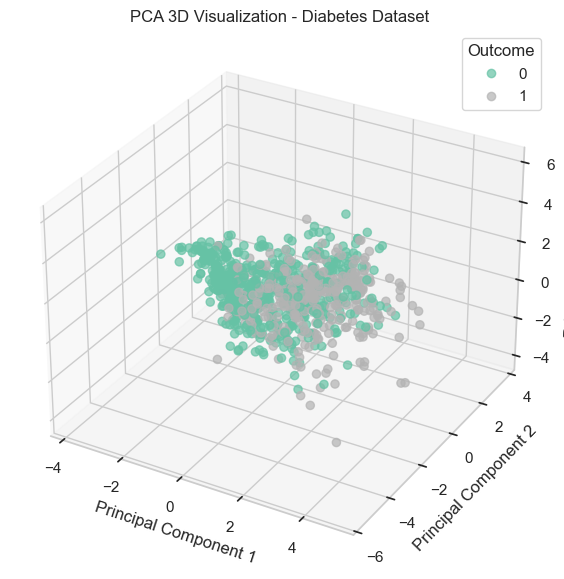

In [21]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_train_pca3[:, 0],
    X_train_pca3[:, 1],
    X_train_pca3[:, 2],
    c=y_train,
    cmap='Set2',
    alpha=0.7,
    s=35
)

ax.set_title('PCA 3D Visualization - Diabetes Dataset')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

plt.legend(*scatter.legend_elements(), title="Outcome")
plt.show()